We will choose the number of neighbors as 10 for knn. If you recall from the last module, for Synergix, k=10 will give us a model closer to a good-fit model. Rest of the code remains the same so will quickly execute all the cells.

In [ ]:
#Importing necessary libraries
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt

#changing the work directory
os.chdir(r'C:\Users\ongja\Downloads\Intro_ML\Module3')

#reading the data
data = pd.read_csv('Synergix_data_preprocessed_new.csv')
data.head()

,Page_traffic,Unit_price,Units_sold,Segment,1_Star_Rating,2_Star_Rating,3_Star_Rating,4_Star_Rating,5_Star_Rating,Image_Count,...,Sum of Spend,Online_Clicks,Online_Cost,Online_Impressions,num_unique_campaigns,Clicks_video,Cost_video,Impressions_video,num_unique_campaigns_offline,Units_sold>1000
0,5835.0,22.214389,2071,Skincare,99.0,72.0,194.0,453.0,3272.0,6.0,...,0.0,1271.0,3102.448115,238075.0,6.0,3479.0,40244.28,3856872.0,2.0,1
1,1881.0,11.870778,681,Skincare,118.0,73.0,200.0,430.0,3084.0,9.0,...,0.0,494.0,1723.716359,75868.0,2.0,0.0,0.00,0.0,0.0,0
2,2477.0,27.645714,875,Makeup,108.0,85.0,232.0,511.0,3402.0,10.0,...,0.0,0.0,0.000000,0.0,0.0,0.0,0.00,0.0,0.0,0
3,4087.0,16.896848,1396,Makeup,82.0,64.0,167.0,303.0,2058.0,5.0,...,0.0,0.0,0.000000,0.0,0.0,0.0,0.00,0.0,0.0,1
4,1446.0,16.357664,822,Hair Care,29.0,24.0,88.0,200.0,1221.0,0.0,...,0.0,0.0,0.000000,0.0,0.0,6024.0,77040.81,7539723.0,2.0,0


In [4]:
#drop Units_sold column
data.drop(columns = 'Units_sold', axis = 1, inplace = True)

In [5]:
#check the data
data.head()

,Page_traffic,Unit_price,Segment,1_Star_Rating,2_Star_Rating,3_Star_Rating,4_Star_Rating,5_Star_Rating,Image_Count,Bullet_Count,...,Sum of Spend,Online_Clicks,Online_Cost,Online_Impressions,num_unique_campaigns,Clicks_video,Cost_video,Impressions_video,num_unique_campaigns_offline,Units_sold>1000
0,5835.0,22.214389,Skincare,99.0,72.0,194.0,453.0,3272.0,6.0,6.0,...,0.0,1271.0,3102.448115,238075.0,6.0,3479.0,40244.28,3856872.0,2.0,1
1,1881.0,11.870778,Skincare,118.0,73.0,200.0,430.0,3084.0,9.0,8.0,...,0.0,494.0,1723.716359,75868.0,2.0,0.0,0.00,0.0,0.0,0
2,2477.0,27.645714,Makeup,108.0,85.0,232.0,511.0,3402.0,10.0,7.0,...,0.0,0.0,0.000000,0.0,0.0,0.0,0.00,0.0,0.0,0
3,4087.0,16.896848,Makeup,82.0,64.0,167.0,303.0,2058.0,5.0,7.0,...,0.0,0.0,0.000000,0.0,0.0,0.0,0.00,0.0,0.0,1
4,1446.0,16.357664,Hair Care,29.0,24.0,88.0,200.0,1221.0,0.0,8.0,...,0.0,0.0,0.000000,0.0,0.0,6024.0,77040.81,7539723.0,2.0,0


In [6]:
#Storing the ratio in a list named Rating_ratio
Rating_ratio = []
for row in data.values:
    if(row[3]+row[4] == 0):
        if(row[6]+row[7] == 0):
            #If all the ratings are zero then overall rating ratio will also be zero
            Rating_ratio.append(0.0)
        else:
            #If only the numerator(1 and 2 star) ratings are zero then add -99999 to the list temporarily which 
            #will be taken care of in the next part of the code
            Rating_ratio.append(-99999)
    else:
        Rating_ratio.append((int(row[6])+int(row[7]))/(int(row[4])+int(row[3])));
              

#replacing -99999 with the maximum rating in the list
max_rating = max(Rating_ratio)
for x in range(len(Rating_ratio)):
    if(Rating_ratio[x] == -99999):
        Rating_ratio[x] = max_rating

In [7]:
#adding the column 'Good_By_Bad_Rating' to the dataframe
data['Good_By_Bad_Rating'] = Rating_ratio

In [8]:
#drop the rating columns
data.drop(columns = ['1_Star_Rating', '2_Star_Rating', '3_Star_Rating', '4_Star_Rating', '5_Star_Rating'], inplace = True)

In [9]:
#check the dataset
data.head().transpose()

,0,1,2,3,4
Page_traffic,5835.0,1881.0,2477.0,4087.0,1446.0
Unit_price,22.214389,11.870778,27.645714,16.896848,16.357664
Segment,Skincare,Skincare,Makeup,Makeup,Hair Care
Image_Count,6.0,9.0,10.0,5.0,0.0
Bullet_Count,6.0,8.0,7.0,7.0,8.0
Title_Count,89.0,126.0,152.0,117.0,165.0
Description_Length,141.0,149.0,186.0,209.0,158.0
num_unique_Search_Terms,3.0,13.0,4.0,7.0,4.0
Organic Search Rank,3.0,16.0,20.0,20.0,16.0
Num_of_Promotions,0.0,0.0,0.0,0.0,0.0


In [10]:
#get the category names
data['Segment'].unique()

array(['Skincare', 'Makeup', 'Hair Care'], dtype=object)

## One-hot Encoding

In [11]:
#one-hot encoding
data = pd.get_dummies(data, columns = ['Segment'], prefix = 'Segment', drop_first = True)
data.head()

,Page_traffic,Unit_price,Image_Count,Bullet_Count,Title_Count,Description_Length,num_unique_Search_Terms,Organic Search Rank,Num_of_Promotions,Sum of Spend,...,Online_Impressions,num_unique_campaigns,Clicks_video,Cost_video,Impressions_video,num_unique_campaigns_offline,Units_sold>1000,Good_By_Bad_Rating,Segment_Makeup,Segment_Skincare
0,5835.0,22.214389,6.0,6.0,89.0,141.0,3.0,3.0,0.0,0.0,...,238075.0,6.0,3479.0,40244.28,3856872.0,2.0,1,21.783626,False,True
1,1881.0,11.870778,9.0,8.0,126.0,149.0,13.0,16.0,0.0,0.0,...,75868.0,2.0,0.0,0.00,0.0,0.0,0,18.397906,False,True
2,2477.0,27.645714,10.0,7.0,152.0,186.0,4.0,20.0,0.0,0.0,...,0.0,0.0,0.0,0.00,0.0,0.0,0,20.274611,True,False
3,4087.0,16.896848,5.0,7.0,117.0,209.0,7.0,20.0,0.0,0.0,...,0.0,0.0,0.0,0.00,0.0,0.0,1,16.171233,True,False
4,1446.0,16.357664,0.0,8.0,165.0,158.0,4.0,16.0,0.0,0.0,...,0.0,0.0,6024.0,77040.81,7539723.0,2.0,0,26.811321,False,False


<h2>Performing Train Test Split</h2>

In [12]:
#Separating the independent and target variables
y = data['Units_sold>1000']
X = data.drop(columns = ['Units_sold>1000'], axis = 1)

In [13]:
#Quick look at the shape of the data
X.shape, y.shape

((19631, 21), (19631,))

In [14]:
#import train test split
from sklearn.model_selection import train_test_split

In [15]:
#split the data into train and test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 42)

In [16]:
#A quick look at the shape of the datasets
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((13741, 21), (5890, 21), (13741,), (5890,))

<h2>Feature Scaling</h2>

In [17]:
#import standard scaler
from sklearn.preprocessing import StandardScaler

In [18]:
#create an instance for StandardScaler
scaler = StandardScaler()

In [19]:
#let's transform the train data
X_train_scaled = scaler.fit_transform(X_train)

In [20]:
#check X_train_scaled
X_train_scaled

array([[ 9.90904284e-04,  4.21592655e-01,  8.49091590e-01, ...,
        -3.73875717e-02,  9.18120514e-01, -6.87701870e-01],
       [ 3.12135911e-01,  9.81193880e-02,  2.35826542e-01, ...,
        -1.02098342e+00,  9.18120514e-01, -6.87701870e-01],
       [-3.87111076e-01,  5.35315189e-01,  4.40248225e-01, ...,
        -5.48287256e-01,  9.18120514e-01, -6.87701870e-01],
       ...,
       [-3.40008100e-01,  1.63678075e-01, -1.39954692e+00, ...,
        -2.47040728e-01,  9.18120514e-01, -6.87701870e-01],
       [-1.19184219e+00,  4.38805436e-01,  4.40248225e-01, ...,
        -1.48075135e+00,  9.18120514e-01, -6.87701870e-01],
       [-1.91298211e+00,  2.89487459e+00,  6.44669908e-01, ...,
         4.19829879e-01, -1.08918163e+00,  1.45411848e+00]],
      shape=(13741, 21))

In [21]:
X_train_scaled.shape

(13741, 21)

In [22]:
X_test_scaled = scaler.transform(X_test)

In [23]:
X_test_scaled

array([[ 0.89130348,  0.60472504,  0.44024822, ..., -1.48075135,
        -1.08918163,  1.45411848],
       [-0.20732366, -0.15943628, -1.39954692, ..., -1.48075135,
         0.91812051, -0.68770187],
       [-1.57861733,  0.45159198, -1.39954692, ...,  0.57902643,
        -1.08918163, -0.68770187],
       ...,
       [-0.73341746,  0.49783078,  0.23582654, ..., -0.05769711,
         0.91812051, -0.68770187],
       [-0.90988776,  0.25377995,  0.64466991, ...,  1.46788558,
         0.91812051, -0.68770187],
       [ 3.0388011 , -0.58786969,  0.03140486, ..., -1.48075135,
         0.91812051, -0.68770187]], shape=(5890, 21))

<h2>KNN Model</h2>

In [24]:
#import the necessary class
from sklearn.neighbors import KNeighborsClassifier

In [25]:
#setting the value k or neighbors at 10 to choose one of the goodfit model
knn_model = KNeighborsClassifier(10)

In [26]:
#training the knn model with train data
knn_model.fit(X_train_scaled, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",10
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.Doesn't affect :meth:`fit` method.",None


In [28]:
#making predictions on the same training data
y_train_pred = knn_model.predict(X_train_scaled)

In [29]:
#making predictions on the test data based on the learniing from fitting model on the train data
y_pred = knn_model.predict(X_test_scaled)

# Video 1.1 - Confusion Matrix and Accuracy

<p style = 'color:green'><b>Run all the cells above before you begin</b><p>

### Step 1: Import Tools

In [35]:
#import confusion matrix
from sklearn.metrics import confusion_matrix

from sklearn.metrics import accuracy_score

### Step 2: Generate Confusion Matrix For Training Data

In [ ]:
# Generate the confusion matrix for train data
"""
1. y_train (Our target values (Units_sold > 1000))
2. y_train_pred ((Model Predictions))
"""
train_cm = confusion_matrix(y_train, y_train_pred)

print("Confusion Matrix for Train Set:")
print(train_cm)

Confusion Matrix for Train Set:
[[4488  952]
 [ 970 7331]]


In our case, when we create the confusion matrix for train data - 
- True Negative (TN) is 4488 - Correctly predicted NO
- False Positive (FP) is 952 - Predicted YES, actually NO
- False Negative (FN) is 970 - Predicted NO, actually YES 
- True Positive (TP) is 7331 - Correctly predicted YES

### Step 3: Generate Confusion Matrix for Test Data

In [33]:
# Generate the confusion matrix for test data
test_cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix for Test Set:")
print(test_cm)


Confusion Matrix for Test Set:
[[1813  541]
 [ 487 3049]]


| Metric | Train Set | Test Set |
|--------|-----------|----------|
| **TN** (Correct NO predictions) | 4488 | 1813 |
| **FP** (False Alarm) | 952 | 541 |
| **FN** (Missed opportunities) | 970 | 487 |
| **TP** (Correct YES predictions) | 7331 | 3049 |
| **Total** | 13,741 | 5,890 |

Accuracy is nothing but the number of correct predictions devided by the total number of predictions. As we discussed, the number of correct predictions are True Positive + True Negative.

So, in terms of confusion matrix, accuracy is the sum of True Positive and True Negatives divided by the total number of predictions.  

**Accuracy = (Number of correct predictions) / (Total predictions)**

![Image Description](Equation_Accuracy.png)

### Step 5: Calculate Accuracy Scores

In [36]:
accuracy_score(y_train, y_train_pred)

0.8601266283385489

**Output**: 0.8601 → 86.01% accuracy on training data

**Calculation**: (4488 + 7331) / 13741 = 11819 / 13741 = 0.8601

In [37]:
accuracy_score(y_test, y_pred)

0.8254668930390492

**Output**: 0.8255 → 82.55% accuracy on test data

**Calculation**: (1813 + 3049) / 5890 = 4862 / 5890 = 0.8255

# Video 1.2 - Precision, Recall and F1 Score

<p style = 'color:green'><b>Run all the cells above before you begin</b><p>

## Section 1: Precision - "When I Say YES, How Often Am I Right?"

In [38]:
#calculating precision on train set
from sklearn.metrics import precision_score
train_precision = precision_score(y_train, y_train_pred)
print(train_precision)

0.885065797416395


In [39]:
#calculating precision on test set
test_precision = precision_score(y_test, y_pred)
print(test_precision)

0.8493036211699164


## Section 2: Recall - "Of All Actual YES Cases, How Many Did I Find?" 

In [40]:
#calculating recall on train set
from sklearn.metrics import recall_score
train_recall = recall_score(y_train, y_train_pred)
print(train_recall)

0.8831466088423081


In [41]:
#calculating recall on test set
test_recall = recall_score(y_test, y_pred)
print(test_recall)

0.8622737556561086


## Section 3: F1 Score - "Balance Between Precision and Recall"

In [42]:
#calculating f1_score on train set
from sklearn.metrics import f1_score
train_f1 = f1_score(y_train, y_train_pred)
print(train_f1)

0.8841051616015436


In [43]:
#calculating precision on test set
test_f1 = f1_score(y_test, y_pred)
print(test_f1)

0.8557395453269716


**Why F1 is useful**: Check to ensure one metric(recall OR precision) isn't being boosted while the other is completely ignored.

### Section 4: Classification Report - All Metrics Together

In [44]:
#create classification for train set
from sklearn.metrics import classification_report
train_classification_report = classification_report(y_train, y_train_pred)
print(train_classification_report)

              precision    recall  f1-score   support

           0       0.82      0.82      0.82      5440
           1       0.89      0.88      0.88      8301

    accuracy                           0.86     13741
   macro avg       0.85      0.85      0.85     13741
weighted avg       0.86      0.86      0.86     13741



In [45]:
#create classification for test set
from sklearn.metrics import classification_report
test_classification_report = classification_report(y_test, y_pred)
print(test_classification_report)

              precision    recall  f1-score   support

           0       0.79      0.77      0.78      2354
           1       0.85      0.86      0.86      3536

    accuracy                           0.83      5890
   macro avg       0.82      0.82      0.82      5890
weighted avg       0.82      0.83      0.83      5890



### Breaking Down the Report:
1. Understanding "Support"
- Support = Number of actual occurrences of that class
- Class 0: 2354 products actually sold <1000 units
- Class 1: 3536 products actually sold >1000 units

2. Macro vs Weighted Average  
    i. Macro Average (Simple Average):  
            - **Precision: (0.79 + 0.85) / 2 = 0.82**  
            - **Note**: Treats both classes equally regardless of size  

    ii. Weighted Average (Size-Adjusted):  
            - **Precision: (0.79 × 2354 + 0.85 × 3536) / 5890 = 0.82**  
            - **Note**: Gives more importance to larger classes  


In [47]:
# [:, 1] <-- All rows and COlumn 1 (probability of class 1)

knn_model.predict_proba(X_test_scaled)[:, 1]

# Returns: Array of probabilities that each product belongs to class 1 (>1000 units)

array([0.9, 0.9, 0. , ..., 0.7, 0.2, 1. ], shape=(5890,))

### .predict_proba() vs .predict()

| Method | What it Returns | Example Output |
|-------|-------|-------|
|*.predict()* | **Hard predictions** (0 or 1) | [1 ,1 ,0 ,1 ,0 , ....]
|*.predict_proba()* | **Probabilities** for each class | [[0.1, 0.9], [0.3, 0.7], ...]


### WHy This Matters

1. Understanding Confidence

In [49]:

print("Product A: probability = 0.9  → Very confident it's class 1")
print("Product B: probability = 0.9  → Very confident it's class 1")
print(".....")
print("Product C: probability = 0.7  → Confident it's class 1")
print("Product D: probability = 0.2  → Not confident it's class 1 (So is confident it's class 0)")
print("Product E: probability = 1.0  → Extremely confident it's class 1")


Product A: probability = 0.9  → Very confident it's class 1
Product B: probability = 0.9  → Very confident it's class 1
.....
Product C: probability = 0.7  → Confident it's class 1
Product D: probability = 0.2  → Not confident it's class 1 (So is confident it's class 0)
Product E: probability = 1.0  → Extremely confident it's class 1


2. Business Flexibility  
You can adjust the threshold based on business needs:

```python
# Conservative (reduce false positives)
threshold = 0.7  # Only stock up when very confident
prediction = (probabilities > 0.7).astype(int)

# Aggressive (reduce false negatives)
threshold = 0.3  # Stock up even when moderately confident
prediction = (probabilities > 0.3).astype(int)
```

# Video 1.3 - AUC-ROC

<p style = 'color:green'><b>Run all the cells above before you begin</b><p>

In [51]:
#calculating AUC-ROC on train set
from sklearn.metrics import roc_curve, auc

In [ ]:
# Calculate ROC Curve
test_fpr, test_tpr, test_thresholds = roc_curve(
    y_test,  # Actual values
    knn_model.predict_proba(X_test_scaled)[:, 1]  # Predicted probabilities
)

#  Calculate AUC (Area Under Curve)
test_roc_auc = auc(test_fpr, test_tpr)
print(test_roc_auc)

0.8931472423947685


|**Variable** | **Meaning** | **Example Values** |
|--|--|--|
|test_fpr | FPR at each threshold | [0.0, 0.05, 0.10, ..., 1.0]
|test_tpr|TPR at each threshold| [0.0, 0.70, 0.85, ..., 1.0]
|test_thresholds|Threshold values tested| [1.0, 0.9, 0.8, ..., 0.0]

**How it works:**
1. Tries every possible threshold in *test_thresholds* (1.0, 0.99, 0.98, ..., 0.01, 0.0)
2. For each threshold, calculates FPR and TPR
3. Returns arrays of these values

**Output**: 0.8931 → 89.31% AUC
#### What is AUC?
- Area Under the ROC Curve
- Single number that summarizes performance across all thresholds
- Ranges from 0 to 1 (higher is better)

### Visualize ROC Curve

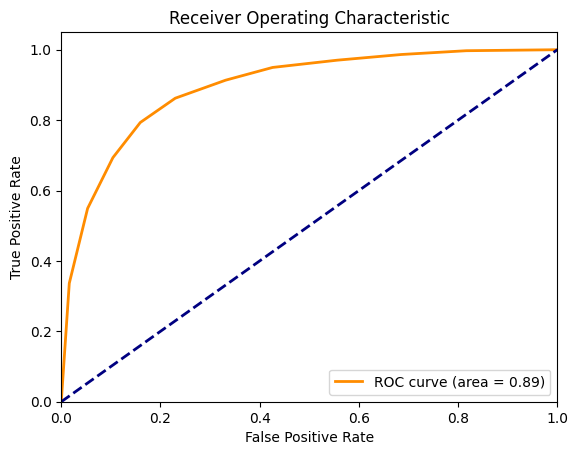

In [53]:
#visualizing AUC-ROC on test set
plt.figure()
plt.plot(test_fpr, test_tpr, color='darkorange', lw=2, label='ROC curve (area = %0.2f)' % test_roc_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

## Train Second Model (k = 50)

**Purpose**: Create a model with k=50 neighbors to compare against k=10

In [55]:
#setting the value k or neighbors at 10 to choose one of the goodfit model
knn_model_50 = KNeighborsClassifier(50)
#training the knn model with train data
knn_model_50.fit(X_train_scaled, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",50
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.Doesn't affect :meth:`fit` method.",None


### Calculate ROC for k=50 Model

In [ ]:
test_fpr_50, test_tpr_50, test_thresholds_50 = roc_curve(
    y_test, 
    knn_model_50.predict_proba(X_test_scaled)[:, 1]
)
test_roc_auc_50 = auc(test_fpr_50, test_tpr_50)

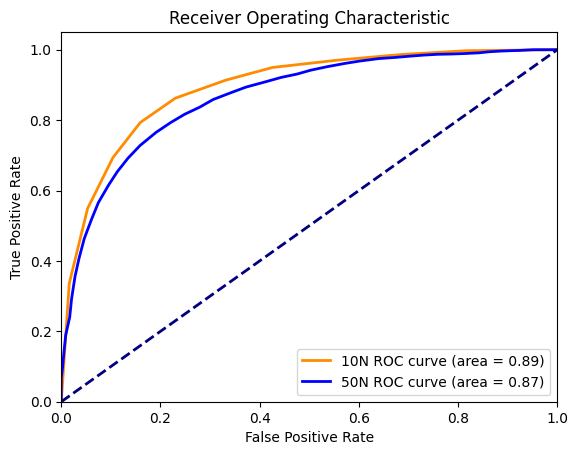

In [58]:
plt.figure()

# k=10 model (orange)
plt.plot(test_fpr, test_tpr, color='darkorange', lw=2, 
         label='10N ROC curve (area = %0.2f)' % test_roc_auc)

# k=50 model (blue)
plt.plot(test_fpr_50, test_tpr_50, color='blue', lw=2, 
         label='50N ROC curve (area = %0.2f)' % test_roc_auc_50)

# Random baseline (diagonal)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

### Understanding the Limitation:
**AUC-ROC requires probability scores:**
- Works with: Logistic Regression, kNN, Random Forest, Neural Networks
- Doesn't work with: Some SVM variants, hard classifiers without probability outputs  
**Solution:**
- Use AUC-ROC when available (it's very informative!)
- For universal comparison across ALL models, use:
    - F1 Score (most common)
    - Accuracy (for balanced datasets)
    - Precision/Recall (for specific business needs)